## An implementation of "An Efficiency-Boosting Client Selection Scheme for Federated Learning With Fairness Guarantee"


In [1]:
import torch
import torchvision
from torchvision.transforms import v2
import torch.nn as nn
import torch.nn.functional as nnFunctional
import torch.optim as optim

import matplotlib.pyplot as plt
import numpy as np
import random

batch_size = 64
num_total_clients = 40 
cold_start = 1 
beta = 0.15
max_clients_selected = 8 
lambda_ridge_regression = 1 
exploration_factor = 0.1 

classes = {0,1,2,3,4,5,6,7,8,9}

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device(torch.accelerator.current_accelerator()
                      .type if torch.accelerator.is_available() else 'cpu')
print(device, 'device detected')

cuda device detected


In [2]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)])

In [3]:
# pull MNIST data
train_mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
train_mnist_loader = torch.utils.data.DataLoader(train_mnist, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
test_mnist = torchvision.datasets.MNIST(root='./data', train=False,
                                       download=True, transform=transform)
test_mnist_loader = torch.utils.data.DataLoader(test_mnist, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

print(f'Number of training examples: {len(train_mnist)}')
print(f'Number of testing examples: {len(test_mnist)}')

100%|██████████| 9.91M/9.91M [00:06<00:00, 1.48MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 137kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.14MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 25.7MB/s]

Number of training examples: 60000
Number of testing examples: 10000


In [4]:
for X, y in train_mnist_loader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_mnist_loader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [5]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    # np.transpose(a=npimg, axes=(0,1,2))
    plt.imshow(np.transpose(a=npimg, axes=(1,2,0)))
    plt.show()

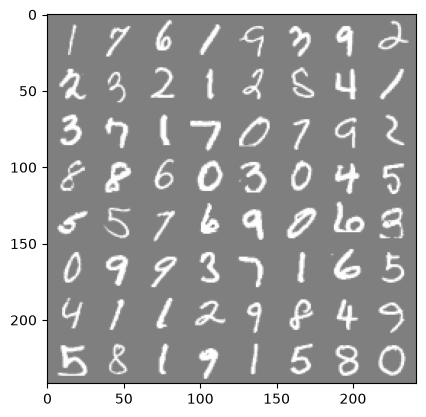

In [6]:
dataiter = iter(train_mnist_loader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))

/tmp/ipykernel_1690/298585832.py:2: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  first_image = np.array(first_image, dtype='float')


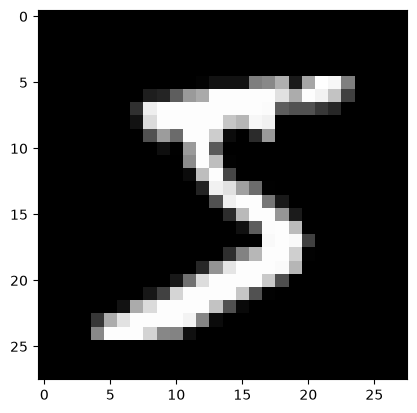

In [7]:
first_image = train_mnist.data[0]
first_image = np.array(first_image, dtype='float')
pixels = first_image.reshape((28, 28))
plt.imshow(pixels, cmap='gray')
plt.show()

In [8]:
"""
Pytorch Multi-Layer Perceptron impl with 2 layers, 200 dense each, 10 factors
"""
class MNIST_mlp2NN():
    def __init__(self):
        self.mlp = nn.Sequential(
            nn.Flatten(),
            torchvision.ops.MLP(
                in_channels=28 * 28,
                hidden_channels=[200, 200, 10],
                activation_layer=nn.ReLU,
            )
        )
        
    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits


if __name__ == "__main__":
    print("\nTesting MNIST Model...")
    mlp_model = MNIST_mlp2NN()
    dummy_tensor = torch.randn(1, 1, 28, 28)
    output = mlp_model.mlp(dummy_tensor)
    print(f"MNIST Output Shape: {output.shape} (Expected: [1, 10])")
    print('model', mlp_model.mlp)


Testing MNIST Model...
MNIST Output Shape: torch.Size([1, 10]) (Expected: [1, 10])
model Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): MLP(
    (0): Linear(in_features=784, out_features=200, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=200, out_features=200, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=200, out_features=10, bias=True)
    (7): Dropout(p=0.0, inplace=False)
  )
)


In [9]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'The model has {count_parameters(mlp_model.mlp):,} trainable parameters')

The model has 199,210 trainable parameters


In [10]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(mlp_model.mlp.parameters(), lr=0.001, momentum=0.9)

In [11]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        # X, y = X, y

        # Compute prediction error
        y_pred = model(X)
        loss = loss_fn(y_pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

In [12]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X, y
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [13]:
epochs = 5
for round in range(epochs):
    print(f"Epoch {round+1}\n-------------------------------")
    train(dataloader=train_mnist_loader, model=mlp_model.mlp, loss_fn=loss_fn, optimizer=optimizer)

print('Finished MNIST Training')
SAVED_MODEL = './mnist_mlp.pt'
torch.save(mlp_model.mlp.state_dict(), SAVED_MODEL)
print("saved mlp model.pt")

Epoch 1
-------------------------------
loss: 2.303614  [   64/60000]
loss: 2.268931  [ 6464/60000]
loss: 2.225163  [12864/60000]
loss: 2.130839  [19264/60000]
loss: 1.974747  [25664/60000]
loss: 1.760503  [32064/60000]
loss: 1.400996  [38464/60000]
loss: 1.037167  [44864/60000]
loss: 0.830698  [51264/60000]
loss: 0.837170  [57664/60000]
Epoch 2
-------------------------------
loss: 0.829016  [   64/60000]
loss: 0.699568  [ 6464/60000]
loss: 0.644605  [12864/60000]
loss: 0.519027  [19264/60000]
loss: 0.519287  [25664/60000]
loss: 0.391874  [32064/60000]
loss: 0.291273  [38464/60000]
loss: 0.348237  [44864/60000]
loss: 0.298679  [51264/60000]
loss: 0.321087  [57664/60000]
Epoch 3
-------------------------------
loss: 0.360246  [   64/60000]
loss: 0.431843  [ 6464/60000]
loss: 0.459900  [12864/60000]
loss: 0.468957  [19264/60000]
loss: 0.404800  [25664/60000]
loss: 0.335709  [32064/60000]
loss: 0.247825  [38464/60000]
loss: 0.408126  [44864/60000]
loss: 0.340100  [51264/60000]
loss: 0.44

In [14]:
test(dataloader=test_mnist_loader, model=mlp_model.mlp, loss_fn=loss_fn)

Test Error: 
 Accuracy: 92.0%, Avg loss: 0.284910 



In [15]:
classes = [
    "0",
    "1",
    "2",
    "3",
    "4",
    "5",
    "6",
    "7",
    "8",
    "9",
]

mlp_model.mlp.eval()
x, y = test_mnist[0][0], test_mnist[0][1]
with torch.no_grad():
    pred = mlp_model.mlp(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')

Predicted: "Sneaker", Actual: "Sneaker"
